# 02. Análise exploratória (passos 1 a 8)

**Fase 3 do pipeline: modelo analítico e visualização.** Os passos seguem a mesma ordem da versão
anterior; em cada um indicamos o que mudou e por quê.

In [1]:
import sys
import warnings
from pathlib import Path

# Encontra a raiz do projeto (a pasta que contém src/sinistros) e importa o pacote
raiz = Path.cwd()
while not (raiz / "src" / "sinistros").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

from sinistros import config, limpeza, analises as an, graficos as gr

df = limpeza.carregar()
print(f'{len(df):,} acidentes')

130,766 acidentes


## Passo 1. Visão geral: volume, evolução e severidade

In [2]:
p1 = an.passo1_descritiva(df)
p1["anual"]

,acidentes,acidentes_fatais,mortos,feridos,letalidade_pct
ano,,,,,
2015,16828,245,255,17680,1.46
2016,18821,240,246,17822,1.28
2017,16669,249,254,16197,1.49
2018,11931,203,210,12954,1.70
2019,11841,188,195,14288,1.59
2020,9229,186,191,11638,2.02
2021,10666,180,182,11035,1.69
2022,10747,148,156,11706,1.38
2023,11294,153,157,12482,1.35


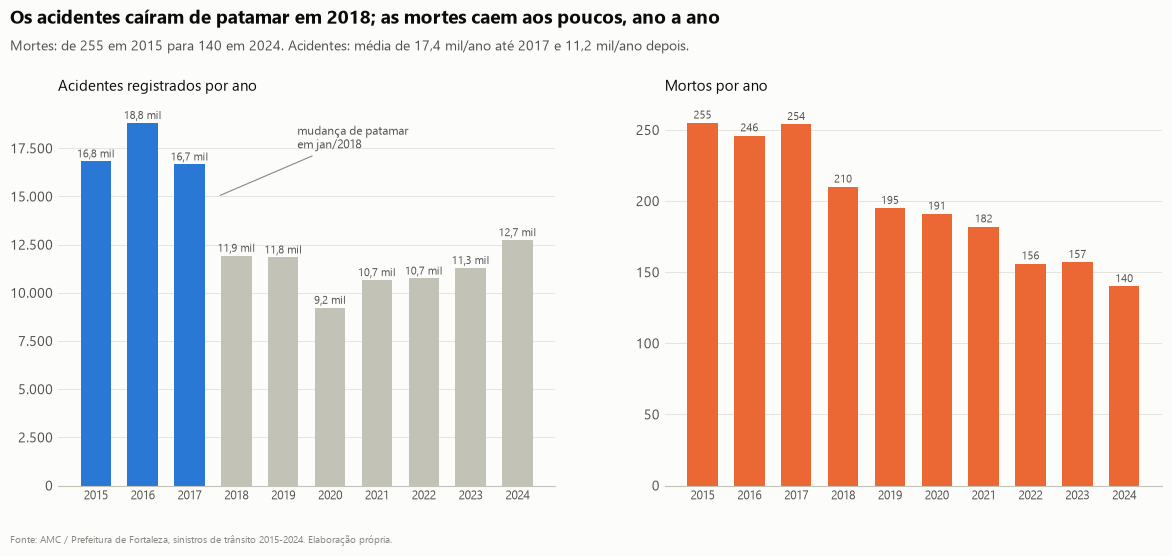

In [3]:
gr.fig02_evolucao_anual(p1);

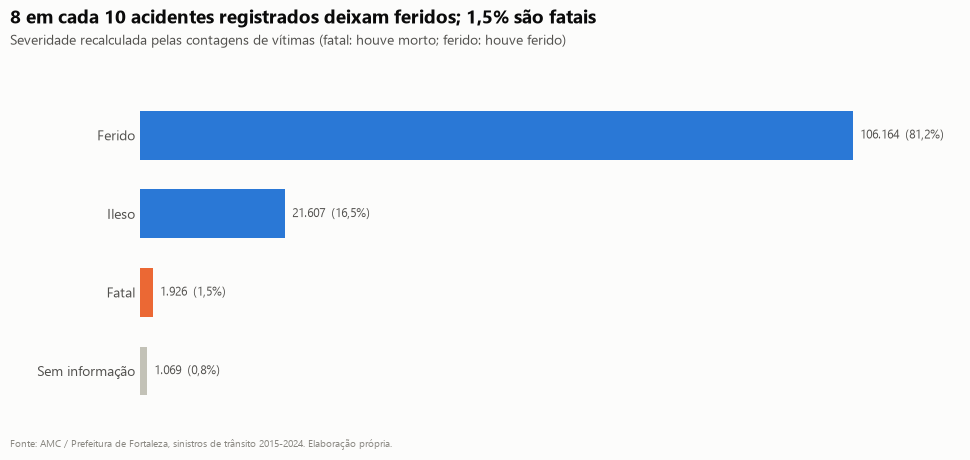

In [4]:
gr.fig03_severidade(p1);

In [5]:
p1['descritivas']

,mean,std,min,50%,max
mortos,0.02,0.13,0.00,0.00,3.00
feridos,1.07,0.70,0.00,1.00,26.00
ilesos,0.53,0.82,0.00,0.00,8.00
vitimas,1.08,0.70,0.00,1.00,26.00
total_veiculos,1.78,0.54,1.00,2.00,19.00


**O que os dados mostram**
- 130.766 acidentes e **1.986 mortos** em 1.926 acidentes fatais (letalidade de 1,47%).
- Os acidentes têm **dois patamares**: cerca de 17,4 mil por ano até 2017 e 11,2 mil por ano de 2018
  em diante. A queda é abrupta em janeiro de 2018 (o passo 11, H3, confirma a data).
- As **mortes caem de forma contínua**: de 255 em 2015 para 140 em 2024.
- 81% dos acidentes registrados têm feridos. Acidentes só com danos materiais tendem a ser menos
  registrados, então a base super-representa os acidentes com vítima.

**O que mudou:** a severidade agora é recalculada pelas vítimas (antes, 7% "não informado" e 3.434
"ilesos" com feridos). Médias de veículos consideram só os acidentes com veículos informados.

## Passo 2. Horários com mais acidentes

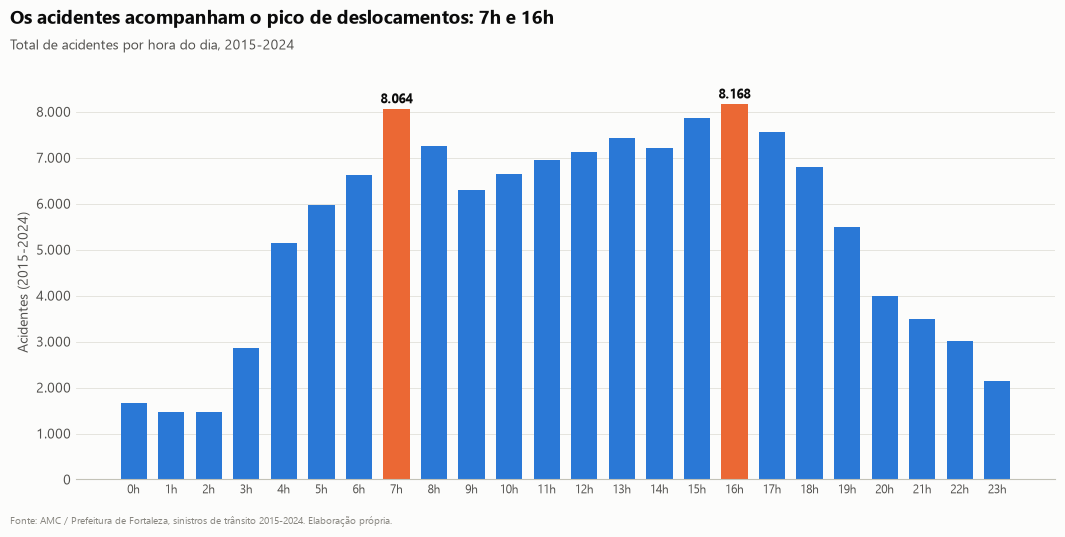

In [6]:
p2 = an.passo2_horarios(df)
gr.fig04_por_hora(p2);

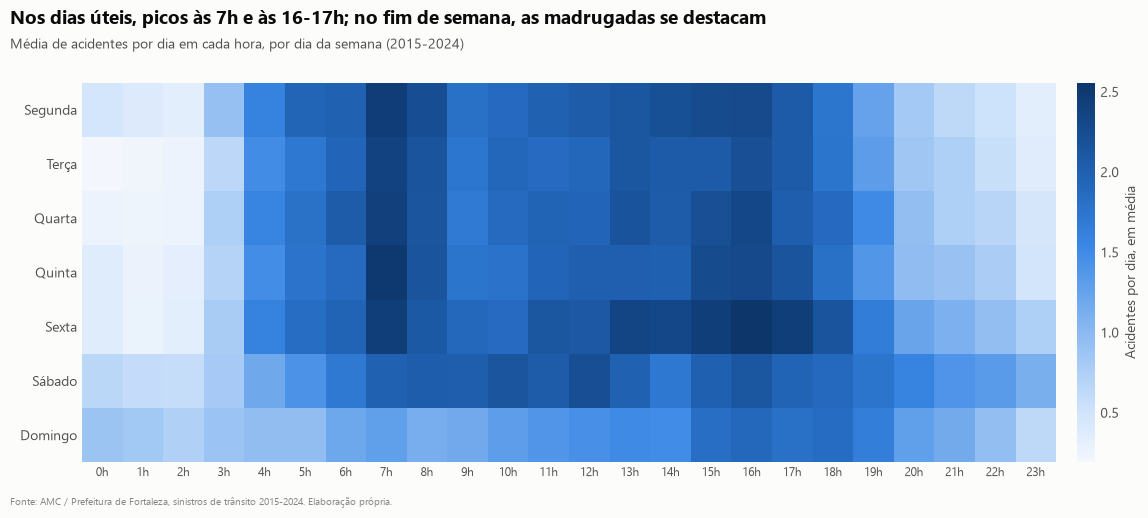

In [7]:
gr.fig05_dia_hora(p2);

**O que os dados mostram**
- Picos às **7h** (8.064) e às **16h** (8.168), coerentes com os deslocamentos casa-trabalho/escola.
- O mapa de calor mostra o padrão por dia: nos dias úteis, picos de manhã e no fim da tarde (a sexta
  à tarde é o horário mais carregado da semana); no sábado e no domingo, a madrugada (0h-3h) tem
  de 2 a 3 vezes mais acidentes por dia que nas madrugadas de dias úteis.

## Passo 3. Faixa horária, fim de semana e letalidade

In [8]:
p3 = an.passo3_faixa_fim_de_semana(df)
pd.DataFrame({"acidentes": p3["por_faixa"],
              "letalidade_%": p3["letalidade_faixa"]["pct"]})

,acidentes,letalidade_%
faixa_horaria,,
Madrugada,18572,2.15
Manhã,41845,1.04
Tarde,45385,1.28
Noite,24964,2.03


In [9]:
p3['media_por_dia_semana'].rename('acidentes por dia (média)')

dia_semana
Segunda   36.25
Terça     34.46
Quarta    35.85
Quinta    35.92
Sexta     39.60
Sábado    38.26
Domingo   30.24
Name: acidentes por dia (média), dtype: float64

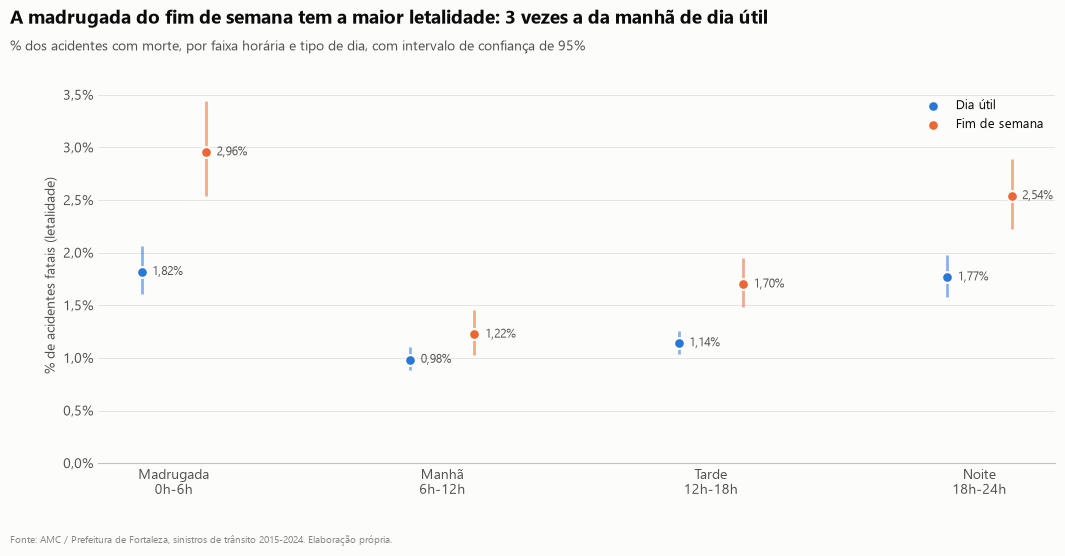

In [10]:
gr.fig06_letalidade_faixa_fds(p3);

**O que os dados mostram**
- Os dias úteis concentram 72,7% dos acidentes, mas porque são 5 dos 7 dias. **Por dia**, o sábado
  (38,3 acidentes/dia) fica no nível dos dias úteis (36,4); só o domingo tem menos (30,2).
- A **letalidade** (% de acidentes com morte) é o que muda: 2,15% de madrugada contra 1,04% de manhã,
  e 1,96% no fim de semana contra 1,29% nos dias úteis. Na madrugada de fim de semana chega a 2,96%,
  **3 vezes** a da manhã de dia útil (0,98%).

**O que mudou:** a afirmação de que fins de semana e madrugadas são mais letais agora vem com
intervalos de confiança; no passo 11 (H1) ela é testada com controle de outros fatores.

## Passo 4. Bairros: totais, taxas por habitante e mortes

In [11]:
p4 = an.passo4_bairros(df)
p4["top_acidentes"][["acidentes", "populacao", "acidentes_10k_hab_ano", "mortos",
                     "mortos_100k_hab_ano"]].head(10)

,acidentes,populacao,acidentes_10k_hab_ano,mortos,mortos_100k_hab_ano
bairro,,,,,
Centro,7257,24096,301.17,73,30.30
Aldeota,5404,42580,126.91,19,4.46
Meireles,4127,38374,107.55,33,8.60
Parangaba,3544,28060,126.30,41,14.61
Fátima,3384,23114,146.40,15,6.49
Messejana,3351,43205,77.56,53,12.27
Mondubim,2724,62440,43.63,50,8.01
Montese,2581,21794,118.43,18,8.26
Barra do Ceará,2108,63477,33.21,48,7.56


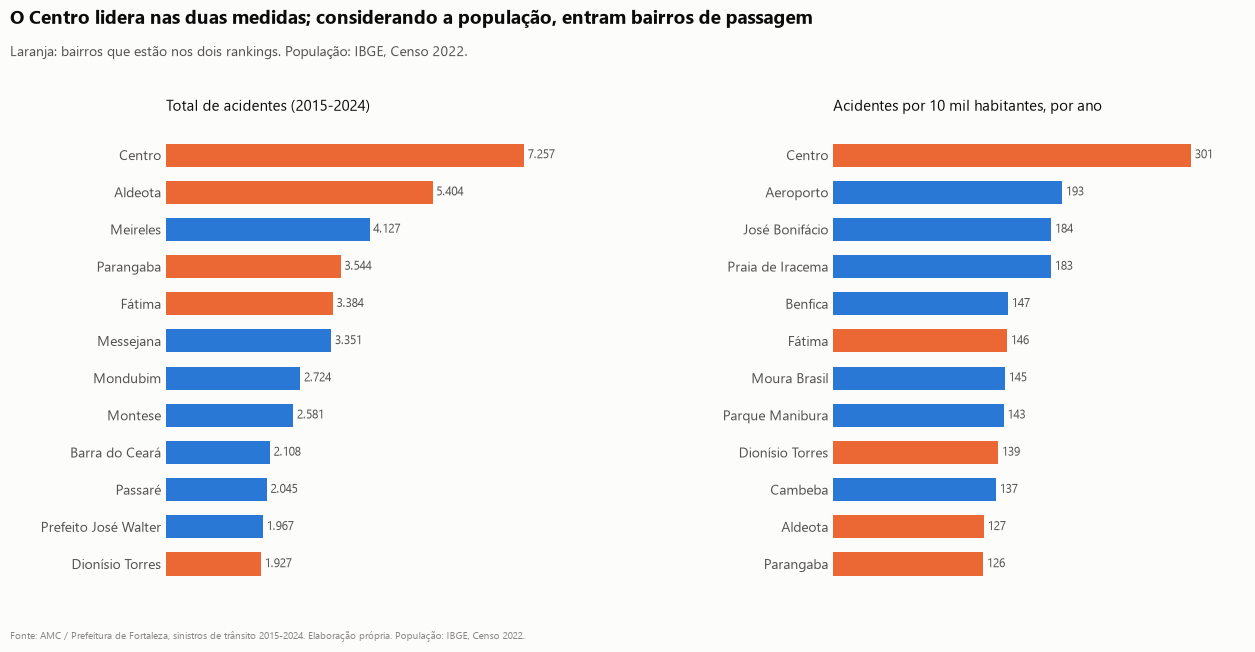

In [12]:
gr.fig07_bairros(p4);

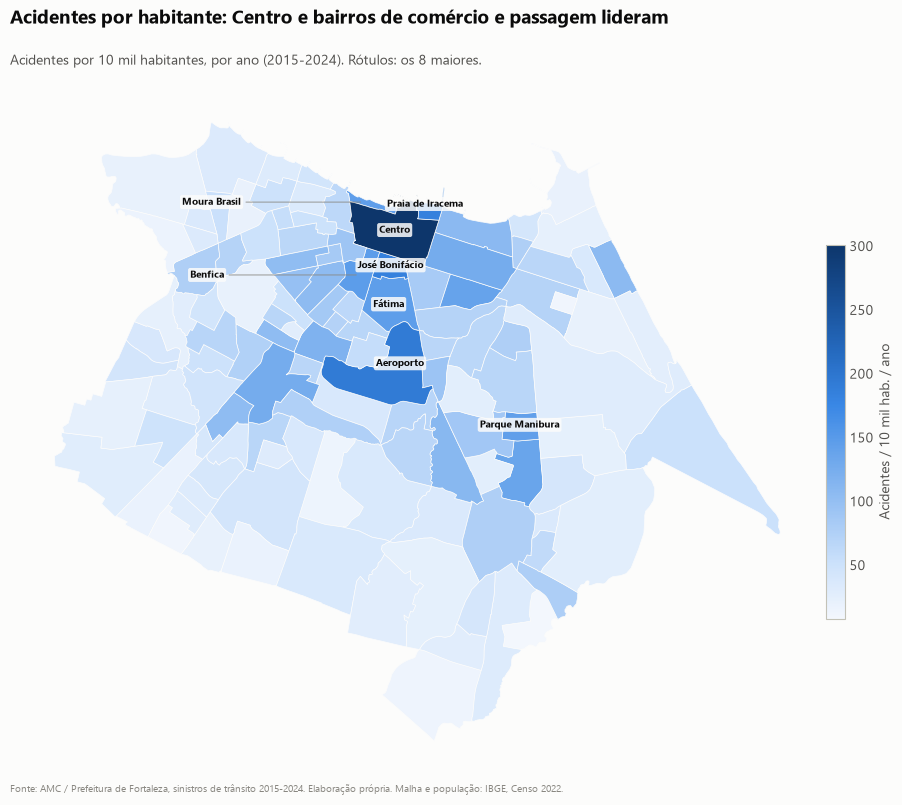

In [13]:
gr.fig08_mapa_taxa_acidentes(p4);

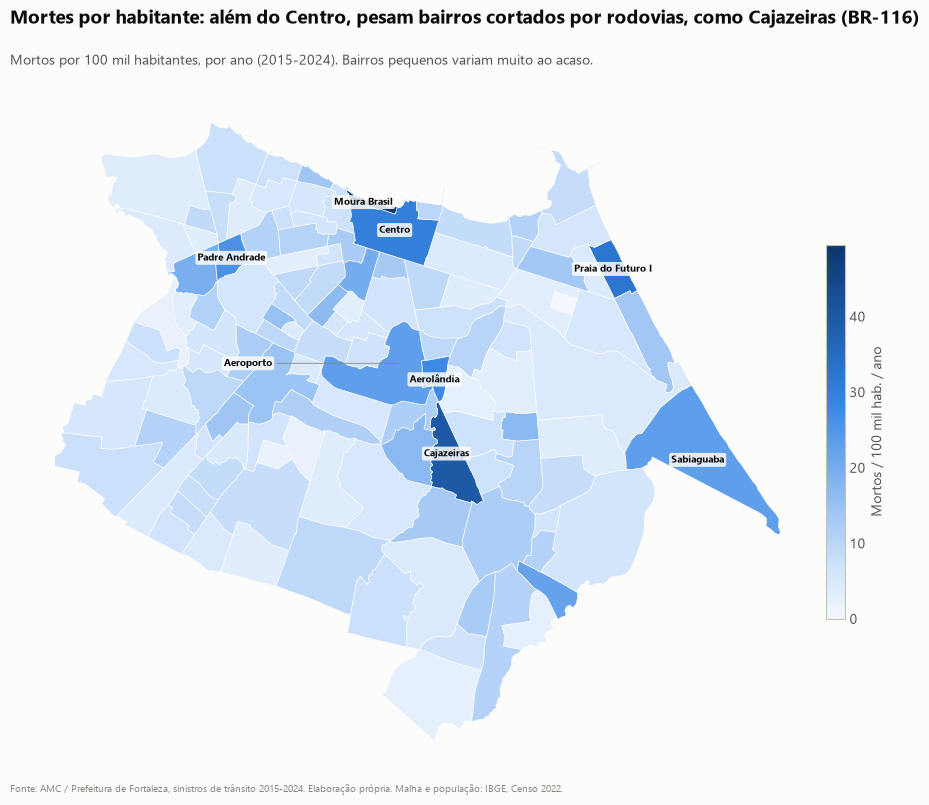

In [14]:
gr.fig09_mapa_mortes(p4);

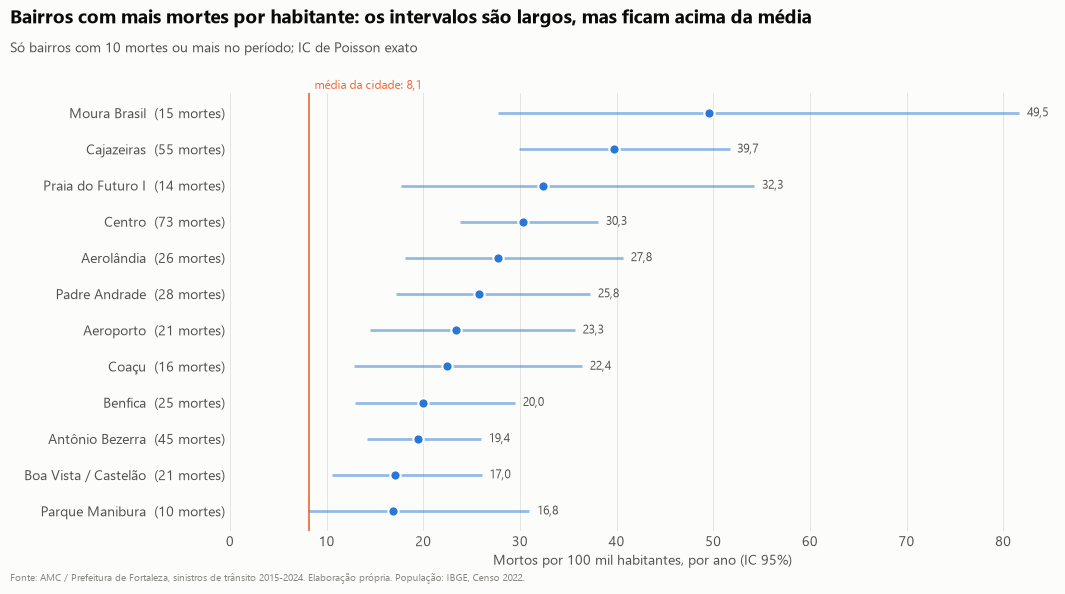

In [15]:
gr.fig10_bairros_mortes_ic(p4);

**O que os dados mostram**
- Em números absolutos, o **Centro** lidera (7.257 acidentes, 5,6%), seguido de Aldeota e Meireles.
- **Por habitante**, o Centro continua muito à frente (301 acidentes por 10 mil hab./ano, contra
  média de 54 na cidade), e entram bairros pequenos e de passagem: Aeroporto, José Bonifácio, Praia
  de Iracema, Benfica. São lugares que **recebem** muito tráfego de quem não mora neles; por isso a
  população residente é só uma medida parcial de exposição (ver H5).
- **Mortes:** Centro (73), Cajazeiras (55) e Messejana (53) lideram em números absolutos. Por
  habitante, Cajazeiras se destaca (39,7 mortes por 100 mil hab./ano, quase 5 vezes a média de 8,1):
  é o bairro com mais acidentes na **BR-116** (880).
- Bairros pequenos têm taxas instáveis (Moura Brasil: 15 mortes, 3 mil habitantes); o gráfico com
  intervalos de confiança mostra essa incerteza.

**O que mudou:** bairro oficial pelas coordenadas (malha IBGE 2022), taxas por habitante com dados do
Censo e intervalos de confiança para as taxas de mortes.

## Passo 5. Veículos envolvidos

In [16]:
p5 = an.passo5_veiculos(df)
p5['presenca'].rename(index=config.NOMES_VEICULOS)

,acidentes,pct_acidentes,veiculos
Automóvel,83431,70.23,109592
Motocicleta,75415,63.48,84768
Ônibus,6290,5.29,6387
Bicicleta,5682,4.78,5692
Caminhão,3803,3.20,3887
Micro-ônibus,750,0.63,753
Ciclomotor,576,0.48,578
Trem,55,0.05,55
Tração animal,13,0.01,13


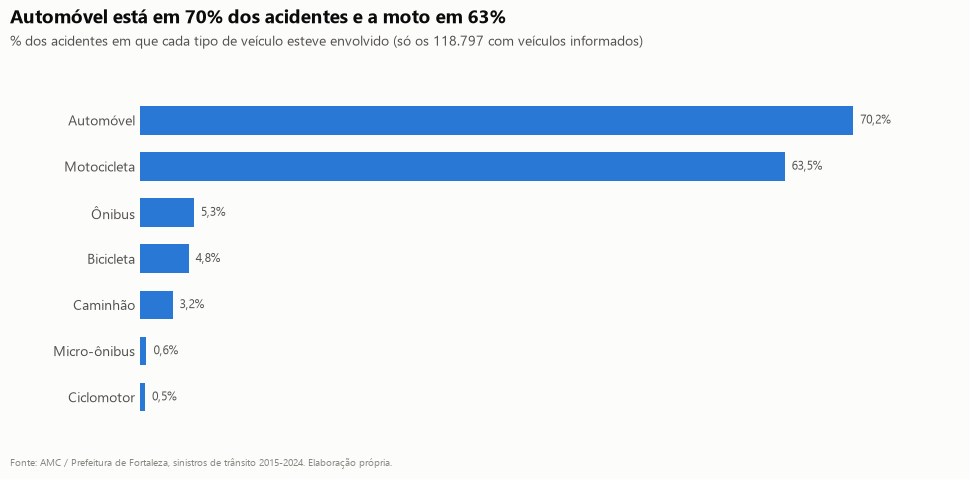

In [17]:
gr.fig11_veiculos(p5);

In [18]:
p5['perfil']

,acidentes,pct
perfil_veiculos,,
Moto + automóvel,45073,37.94
Só automóvel,29996,25.25
Só moto,27582,23.22
Envolve ônibus/caminhão,10430,8.78
Envolve bicicleta,5682,4.78
Outros,34,0.03


**O que os dados mostram**
- Entre os 118.797 acidentes com veículos informados, o **automóvel está em 70%** e a **moto em 63%**.
- A medida certa é "% dos acidentes com o veículo", e não "% dos veículos" (usada antes): um
  engavetamento com 5 carros não é 5 acidentes.

**O que mudou:** exclusão dos 11.969 acidentes sem veículos informados, que antes contavam como
acidentes "sem" cada tipo de veículo.

## Passo 6. Co-ocorrência de veículos

In [19]:
p6 = an.passo6_coocorrencia(df)
p6['matriz']

,Automóvel,Motocicleta,Ônibus,Bicicleta,Caminhão
Automóvel,29976,44937,3739,2141,2030
Motocicleta,44937,27470,1401,326,1312
Ônibus,3739,1401,920,173,127
Bicicleta,2141,326,173,3022,43
Caminhão,2030,1312,127,43,373


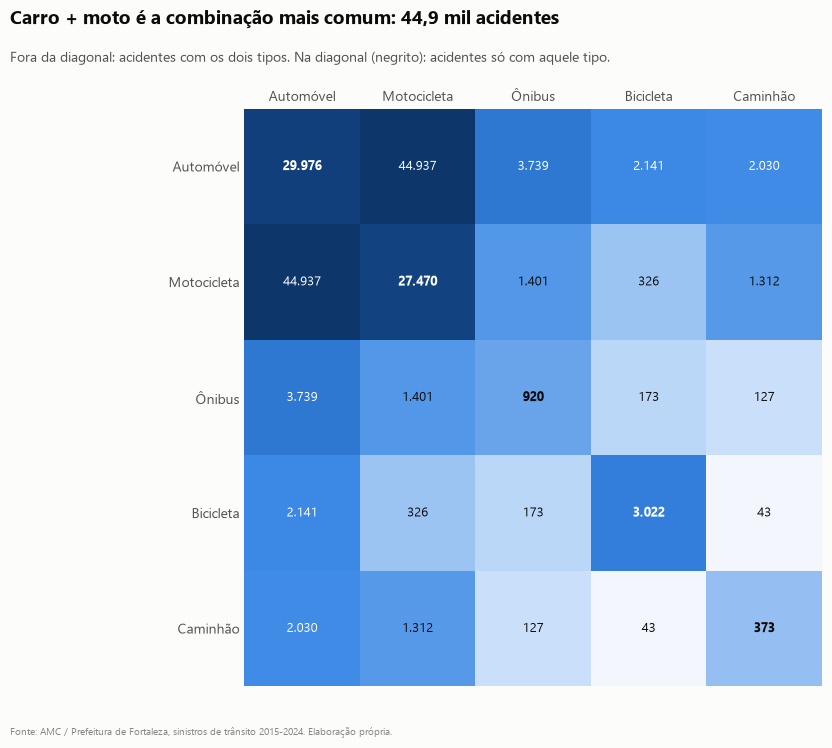

In [20]:
gr.fig12_coocorrencia(p6);

**O que os dados mostram**
- **Carro + moto** é a combinação mais comum (44.937 acidentes).
- Acidentes **só** com automóveis: 29.976; **só** com motos: 27.470 (inclui quedas e atropelamentos
  de pedestres, que não aparecem como veículo).
- Bicicletas se envolvem principalmente com automóveis (2.141) e bem menos com motos (326).

**O que mudou:** a versão anterior chamava de "exclusivamente automóveis" os 83 mil acidentes que
tinham automóvel **com ou sem** outros veículos. Agora a diagonal mostra de fato os acidentes com um
só tipo de veículo.

## Passo 7. Letalidade por veículo, natureza e horário

In [21]:
p7 = an.passo7_letalidade(df)
p7['por_veiculo']

,n,eventos,pct,ic_inf,ic_sup,amostra_pequena
veiculo,,,,,,
Tração animal,13,3,23.08,8.18,50.26,True
Trem,55,7,12.73,6.30,24.02,True
Ciclomotor,576,30,5.21,3.67,7.34,True
Caminhão,3803,146,3.84,3.27,4.50,False
Ônibus,6290,223,3.55,3.12,4.03,False
Bicicleta,5682,164,2.89,2.48,3.35,False
Micro-ônibus,750,15,2.00,1.22,3.27,True
Motocicleta,75415,1202,1.59,1.51,1.69,False
Automóvel,83431,837,1.00,0.94,1.07,False


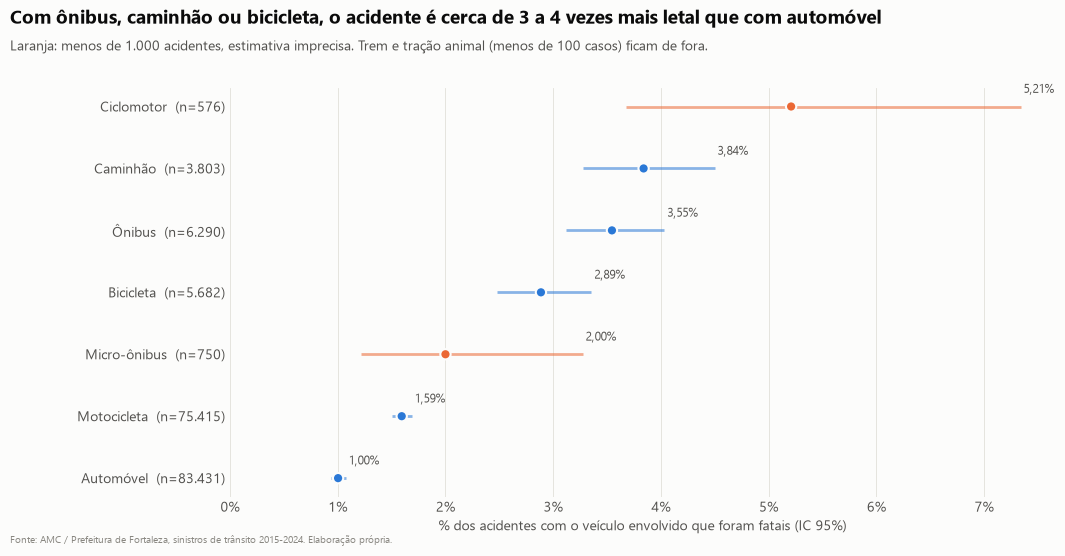

In [22]:
gr.fig13_letalidade_veiculo(p7);

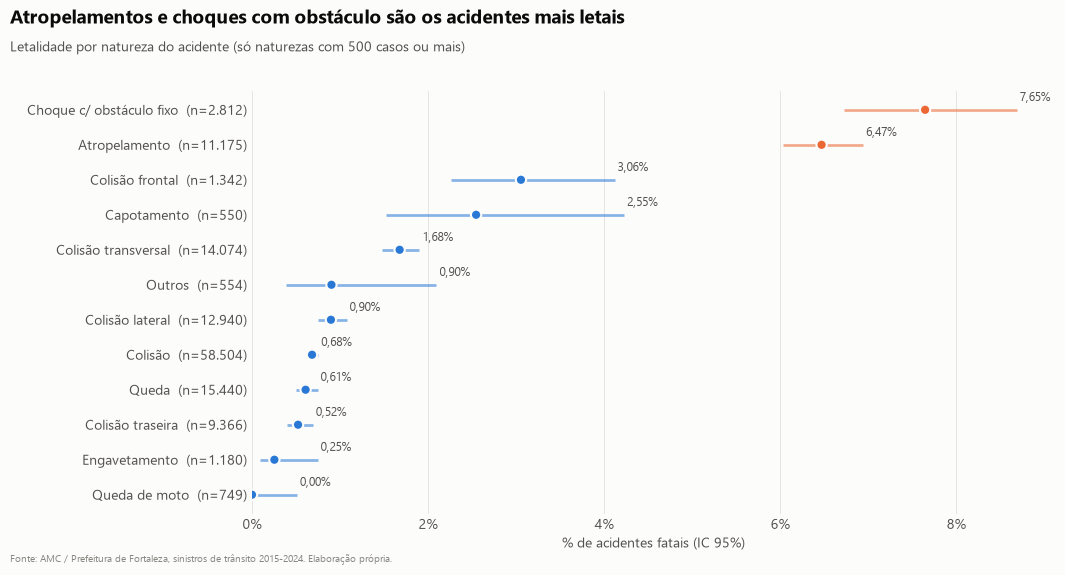

In [23]:
gr.fig14_letalidade_natureza(p7);

**O que os dados mostram**
- Acidentes com **caminhão** (3,8%), **ônibus** (3,5%) e **bicicleta** (2,9%) são cerca de 3 a 4
  vezes mais letais que os com automóvel (1,0%). Moto fica em 1,6%.
- **Ciclomotor** (5,2%) tem a maior letalidade, mas com só 576 acidentes o intervalo vai de 3,7% a
  7,3%: é preciso cautela. Trem e tração animal têm menos de 100 casos e ficam de fora.
- Pela natureza: **choque com obstáculo fixo** (7,6%) e **atropelamento** (6,5%) são de longe os
  mais letais. Os atropelamentos somam 11 mil acidentes e 723 acidentes fatais, **38% de todos os
  acidentes fatais** da cidade.

**O que mudou:** intervalos de confiança e aviso de amostra pequena; inclusão da natureza do acidente.

## Passo 8. Correlação entre as variáveis numéricas

In [24]:
p8 = an.passo8_correlacao(df)
p8['matriz'].round(2)

,Mortos,Feridos,Ilesos,Automóvel,Motocicleta,Ônibus,Bicicleta,Caminhão,Total de veículos
Mortos,1.00,-0.12,0.01,-0.08,-0.00,0.04,0.02,0.03,-0.08
Feridos,-0.12,1.00,-0.58,-0.22,0.34,-0.12,0.01,-0.08,-0.01
Ilesos,0.01,-0.58,1.00,0.45,-0.37,0.21,-0.10,0.11,0.34
Automóvel,-0.08,-0.22,0.45,1.00,-0.58,-0.09,-0.17,-0.08,0.59
Motocicleta,-0.00,0.34,-0.37,-0.58,1.00,-0.20,-0.26,-0.11,0.07
Ônibus,0.04,-0.12,0.21,-0.09,-0.20,1.00,-0.02,-0.02,0.07
Bicicleta,0.02,0.01,-0.10,-0.17,-0.26,-0.02,1.00,-0.03,-0.13
Caminhão,0.03,-0.08,0.11,-0.08,-0.11,-0.02,-0.03,1.00,0.08
Total de veículos,-0.08,-0.01,0.34,0.59,0.07,0.07,-0.13,0.08,1.00


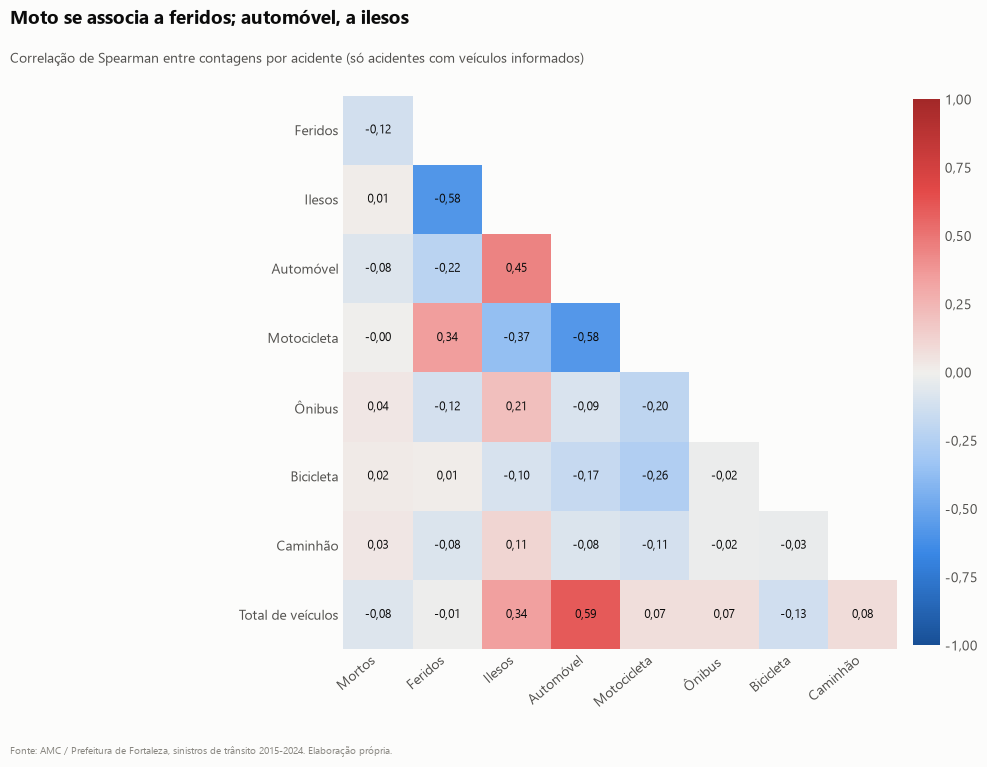

In [25]:
gr.fig15_correlacao(p8);

**O que os dados mostram**
- **Moto e feridos** (ρ = 0,34): mais motos, mais feridos. **Automóvel e ilesos** (ρ = 0,45): os
  ocupantes de carro saem mais ilesos.
- Automóvel e total de veículos (ρ = 0,59) é em boa parte estrutural (o total é a soma dos tipos).
- Nenhuma variável se correlaciona com o número de mortos: morte é um evento raro (1,5%), e a
  correlação linear não é a ferramenta certa para eventos raros. A letalidade é analisada com taxas
  (passo 7) e regressão logística (passo 11).

**O que mudou:** Spearman no lugar de Pearson (contagens pequenas e assimétricas) e só acidentes
com veículos informados.